# SQL Analysis and Visualization
This notebook executes the analytical views defined in `db/views.sql`, visualizes key performance metrics, and extracts insights regarding user behavior, swap patterns, and order conversions.

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from config import DATABASE_URL
from sqlalchemy import create_engine

# Visualization style preferences
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Quick connection test using the engine
engine = create_engine(DATABASE_URL)
with engine.connect() as conn:
    print("Successfully connected to the local PostgreSQL database via config!")

Successfully connected to the local PostgreSQL database via config!


## 1. Recipe & Meal Role Performance Analysis
Loading the `v_recipe_performance` view to evaluate acceptance, swap, skip, and cook rates across different meal roles.

,Meal Role,Total Interactions,Cooked,Cooked %,Not Cooked,Not Cooked %,Swapped,Swapped %,Skipped,Skipped %,Accepted,Accepted %
5,Main,24212,13106,54.1,1792,7.4,3056,12.6,2573,10.6,3685,15.2
0,Anchor,20919,11679,55.8,1678,8.0,2188,10.5,2030,9.7,3344,16.0
4,Lentil,6338,3459,54.6,482,7.6,720,11.4,705,11.1,972,15.3
7,Snack,3907,1850,47.4,249,6.4,684,17.5,607,15.5,517,13.2
1,Beverage,3249,1901,58.5,276,8.5,263,8.1,268,8.2,541,16.7
2,Condiment,3091,1820,58.9,263,8.5,224,7.2,259,8.4,525,17.0
8,Yogurt Side,1918,1079,56.3,165,8.6,179,9.3,176,9.2,319,16.6
3,Dessert,1656,850,51.3,128,7.7,227,13.7,222,13.4,229,13.8
6,Salad,1550,806,52.0,115,7.4,227,14.6,188,12.1,214,13.8


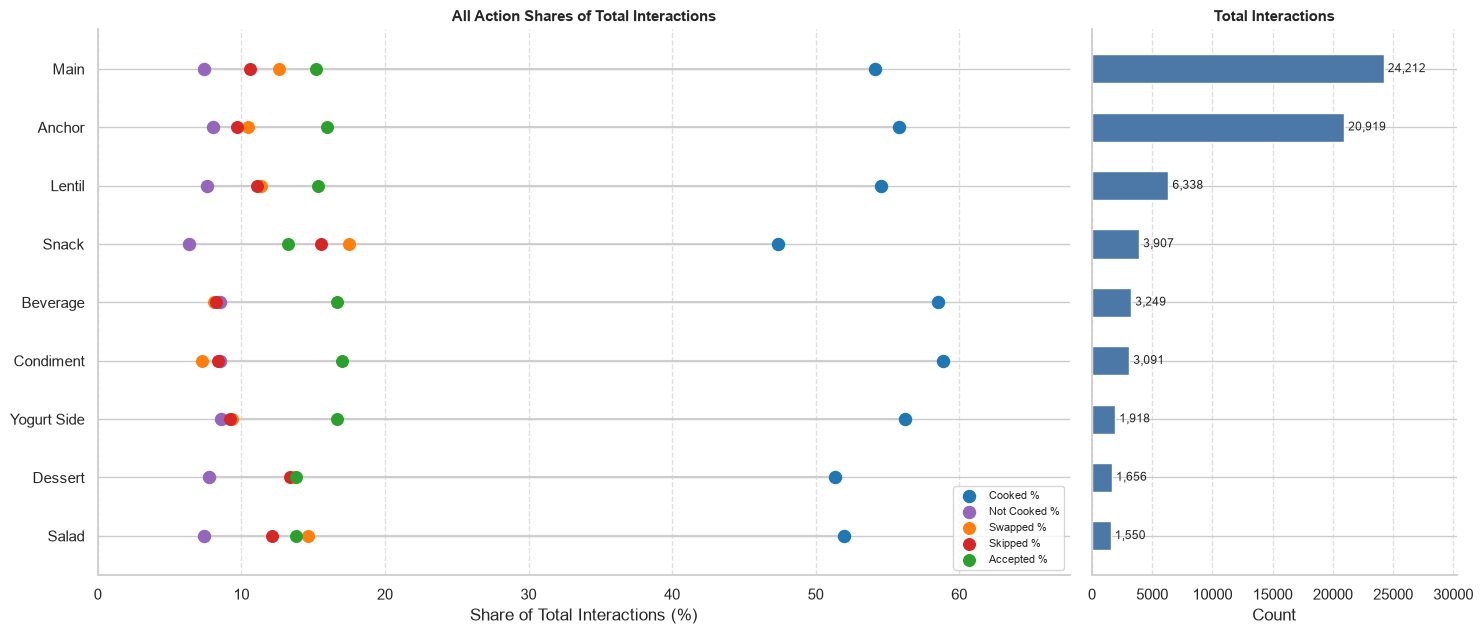

In [18]:
# Query the v_recipe_performance view and build df_meal_role
query_recipe_perf = "SELECT * FROM v_recipe_performance;"
df_recipe_perf = pd.read_sql(query_recipe_perf, engine)

count_defaults = {
    "total_interactions": 0,
    "cooked_count": 0,
    "accepted_count": 0,
    "not_cooked_count": 0,
    "swapped_count": 0,
    "skipped_count": 0,
}

rate_to_count = {
    "cook_rate_pct": "cooked_count",
    "acceptance_rate_pct": "accepted_count",
    "not_cooked_rate_pct": "not_cooked_count",
    "swap_rate_pct": "swapped_count",
    "skip_rate_pct": "skipped_count",
}

# Add missing count columns with zero defaults
for col, default_val in count_defaults.items():
    if col not in df_recipe_perf.columns:
        df_recipe_perf[col] = default_val

# Estimate counts from rate columns when count columns are all zero
for rate_col, count_col in rate_to_count.items():
    if df_recipe_perf[count_col].eq(0).all() and rate_col in df_recipe_perf.columns:
        df_recipe_perf[count_col] = (
            df_recipe_perf["total_interactions"] * df_recipe_perf[rate_col] / 100.0
        )

# Sum counts by meal_role
df_meal_role = (
    df_recipe_perf.groupby("meal_role", as_index=False)
    .agg(
        total_interactions=("total_interactions", "sum"),
        cooked_count=("cooked_count", "sum"),
        accepted_count=("accepted_count", "sum"),
        not_cooked_count=("not_cooked_count", "sum"),
        swapped_count=("swapped_count", "sum"),
        skipped_count=("skipped_count", "sum"),
    )
    .sort_values("total_interactions", ascending=False)
)

# Compute action shares relative to total_interactions
for outcome, count_col in [
    ("Swapped", "swapped_count"),
    ("Skipped", "skipped_count"),
    ("Accepted", "accepted_count"),
]:
    df_meal_role[f"{outcome}_pct"] = np.where(
        df_meal_role["total_interactions"] > 0,
        100.0 * df_meal_role[count_col] / df_meal_role["total_interactions"],
        0.0,
    )

# Sort both the combined table and the graph by total_interactions
sort_col = "total_interactions"

# Prepare role labels and cooked/not-cooked shares relative to total_interactions
df_plot_total = df_meal_role.copy()
df_plot_total["role_label"] = (
    df_plot_total["meal_role"].str.replace("_", " ", regex=False).str.title()
)
df_plot_total["Cooked_total_pct"] = np.where(
    df_plot_total["total_interactions"] > 0,
    100.0 * df_plot_total["cooked_count"] / df_plot_total["total_interactions"],
    0.0,
)
df_plot_total["Not_Cooked_total_pct"] = np.where(
    df_plot_total["total_interactions"] > 0,
    100.0 * df_plot_total["not_cooked_count"] / df_plot_total["total_interactions"],
    0.0,
)

# Sort descending for the table so the highest interaction count appears first
df_sorted_desc = df_plot_total.sort_values(sort_col, ascending=False)

# Build one table with counts and action shares for each meal role
table_combined = pd.DataFrame({
    "Meal Role": df_sorted_desc["role_label"],
    "Total Interactions": df_sorted_desc["total_interactions"].round(0).astype(int),
    "Cooked": df_sorted_desc["cooked_count"].round(0).astype(int),
    "Cooked %": df_sorted_desc["Cooked_total_pct"].round(1),
    "Not Cooked": df_sorted_desc["not_cooked_count"].round(0).astype(int),
    "Not Cooked %": df_sorted_desc["Not_Cooked_total_pct"].round(1),
    "Swapped": df_sorted_desc["swapped_count"].round(0).astype(int),
    "Swapped %": df_sorted_desc["Swapped_pct"].round(1),
    "Skipped": df_sorted_desc["skipped_count"].round(0).astype(int),
    "Skipped %": df_sorted_desc["Skipped_pct"].round(1),
    "Accepted": df_sorted_desc["accepted_count"].round(0).astype(int),
    "Accepted %": df_sorted_desc["Accepted_pct"].round(1),
})

display(table_combined)

# Sort ascending for horizontal plotting so the top row matches the top of the table
df_plot_sorted = df_plot_total.sort_values(sort_col, ascending=True)

# Create side-by-side dot plot for action shares and bar chart for volume
fig, (ax_rates, ax_vol) = plt.subplots(
    1,
    2,
    figsize=(15, 6.5),
    sharey=True,
    gridspec_kw={"width_ratios": [3.2, 1.2]},
)

action_series = [
    ("Cooked_total_pct", "Cooked %", "#1f77b4", 75),
    ("Not_Cooked_total_pct", "Not Cooked %", "#9467bd", 75),
    ("Swapped_pct", "Swapped %", "#ff7f0e", 70),
    ("Skipped_pct", "Skipped %", "#d62728", 70),
    ("Accepted_pct", "Accepted %", "#2ca02c", 70),
]

for col, label, color, size in action_series:
    ax_rates.scatter(df_plot_sorted[col], df_plot_sorted["role_label"], color=color, s=size, label=label)

# Draw range lines across action shares for each meal role
for _, row in df_plot_sorted.iterrows():
    vals = [row[col] for col, _, _, _ in action_series]
    ax_rates.plot(
        [min(vals), max(vals)],
        [row["role_label"], row["role_label"]],
        color="#d0d0d0",
        zorder=0,
    )

max_pct = (
    df_plot_sorted[[col for col, _, _, _ in action_series]].to_numpy().max()
    if not df_plot_sorted.empty
    else 50
)
ax_rates.set_title("All Action Shares of Total Interactions", fontsize=11, weight="bold")
ax_rates.set_xlabel("Share of Total Interactions (%)")
ax_rates.set_xlim(0, max(max_pct * 1.15, 20))
ax_rates.grid(axis="x", linestyle="--", alpha=0.6)
ax_rates.legend(loc="lower right", frameon=True, fontsize=8)
sns.despine(ax=ax_rates)

# Plot total interactions per meal role on the right panel
bars_vol = ax_vol.barh(
    df_plot_sorted["role_label"],
    df_plot_sorted["total_interactions"],
    color="#4c78a8",
    height=0.5,
)
ax_vol.set_title("Total Interactions", fontsize=11, weight="bold")
ax_vol.set_xlabel("Count")
ax_vol.set_xlim(0, max(df_plot_sorted["total_interactions"].max() * 1.25, 1))
ax_vol.bar_label(bars_vol, fmt="{:,.0f}", padding=3, fontsize=8.5)
ax_vol.grid(axis="x", linestyle="--", alpha=0.6)
sns.despine(ax=ax_vol)

plt.tight_layout()
plt.show()

## 2. Most Common Swap Pairs ($A \rightarrow B$ Transitions)
Analyzing the `v_common_swap_pairs` view to identify which dishes users frequently swap away from and what they substitute them with.

,transition_label,transition_count,original_meal_role
0,Kakdi Salad → Kheera Salad [salad],18,salad
1,Kheera Salad → Kakdi Salad [salad],16,salad
2,Kakdi Raita → Kheera Raita [yogurt_side],16,yogurt_side
3,Kheera Raita → Kakdi Raita [yogurt_side],14,yogurt_side
4,Sakinalu → Ela Ada [snack],12,snack
5,Karikku → Shikanji [beverage],10,beverage
6,Sesame Laddu → Sweet Sevai [dessert],9,dessert
7,Ragi Java → Karikku [beverage],8,beverage


,label,net_swap_score
57,Spinach Mash [main],-13.0
53,Arbi Fry [main],-13.0
47,Onion Samosa [snack],-12.0
192,Parippu Curry [lentil],-12.0
362,Vendakkai Poriyal [main],-12.0
553,Kerala Matta Rice [anchor],15.0
925,Capsicum Koora [main],15.0
377,Neer Dosa [anchor],16.0
449,Mint Rice [anchor],17.0
36,Green Gram Sundal [snack],17.0


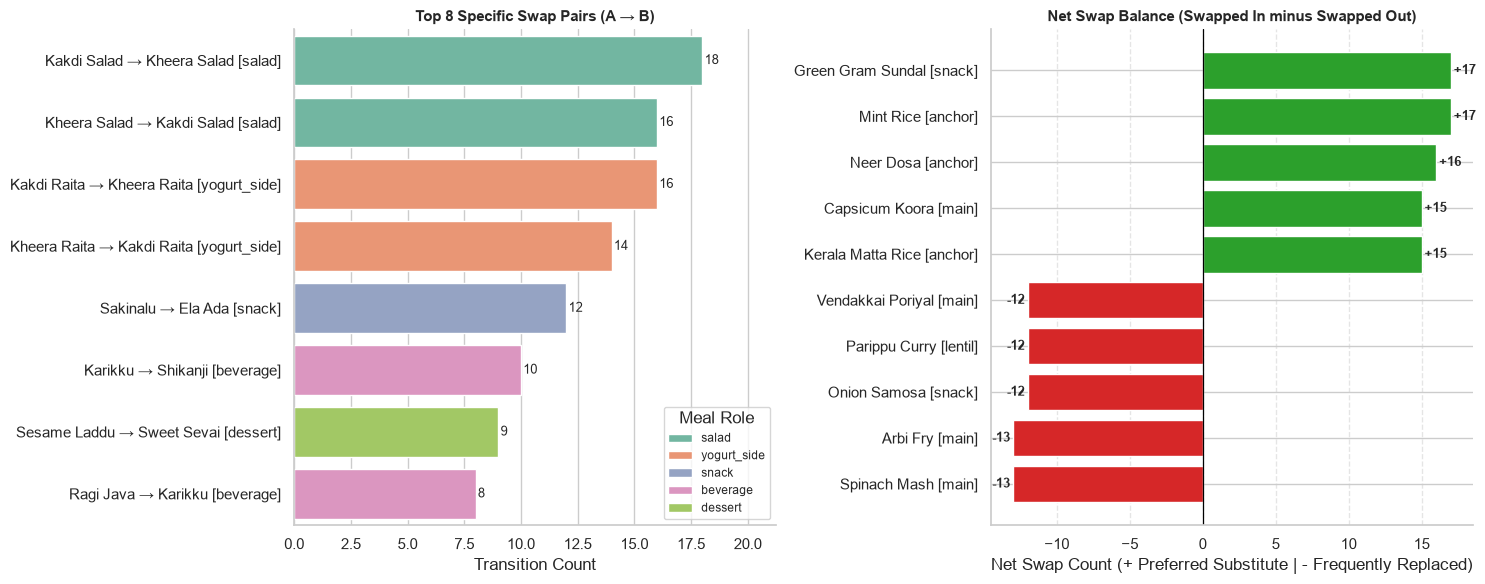

In [ ]:
# Query top swap pairs
query_swap_pairs = "SELECT * FROM v_common_swap_pairs;"
df_swap_pairs = pd.read_sql(query_swap_pairs, engine)

# Calculate net swap score per recipe across all recorded transitions
out_counts = df_swap_pairs.groupby(['original_recipe_code', 'original_recipe_name', 'original_meal_role'])['transition_count'].sum().reset_index()
out_counts.columns = ['recipe_code', 'recipe_name', 'meal_role', 'swapped_out']

in_counts = df_swap_pairs.groupby(['swapped_to_recipe_code', 'swapped_to_recipe_name', 'swapped_to_meal_role'])['transition_count'].sum().reset_index()
in_counts.columns = ['recipe_code', 'recipe_name', 'meal_role', 'swapped_in']

df_net_recipes = pd.merge(out_counts, in_counts, on=['recipe_code', 'recipe_name', 'meal_role'], how='outer').fillna(0)
df_net_recipes['net_swap_score'] = df_net_recipes['swapped_in'] - df_net_recipes['swapped_out']
df_net_recipes['label'] = df_net_recipes['recipe_name'] + ' [' + df_net_recipes['meal_role'] + ']'

# Select top 5 most "Swapped Into" (Favorites) and top 5 most "Swapped Out Of" (Rejected)
top_gainers = df_net_recipes.nlargest(5, 'net_swap_score')
top_losers = df_net_recipes.nsmallest(5, 'net_swap_score')
df_extremes = pd.concat([top_gainers, top_losers]).drop_duplicates().sort_values('net_swap_score', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Top 8 Specific Pair Transitions
top_swaps = df_swap_pairs.head(8).copy()
top_swaps['transition_label'] = (
    top_swaps['original_recipe_name'] + ' → ' + top_swaps['swapped_to_recipe_name'] +
    ' [' + top_swaps['original_meal_role'] + ']'
)

display(top_swaps[['transition_label', 'transition_count', 'original_meal_role']])
display(df_extremes[['label', 'net_swap_score']])

sns.barplot(
    data=top_swaps,
    x='transition_count',
    y='transition_label',
    hue='original_meal_role',
    dodge=False,
    palette='Set2',
    ax=ax1
)
ax1.set_title('Top 8 Specific Swap Pairs (A → B)', fontsize=11, weight='bold')
ax1.set_xlabel('Transition Count')
ax1.set_ylabel('')
ax1.set_xlim(0, top_swaps['transition_count'].max() * 1.18)
ax1.legend(title='Meal Role', loc='lower right', fontsize=8.5)
for p in ax1.patches:
    w = p.get_width()
    if w > 0:
        ax1.annotate(f'{int(w)}', (w + 0.1, p.get_y() + p.get_height()/2), va='center', fontsize=9)

# Panel 2: Diverging Bar Chart of Net Swap Gain/Loss
colors = ['#d62728' if x < 0 else '#2ca02c' for x in df_extremes['net_swap_score']]
ax2.barh(df_extremes['label'], df_extremes['net_swap_score'], color=colors)
ax2.axvline(0, color='black', linewidth=0.9)
ax2.set_title('Net Swap Balance (Swapped In minus Swapped Out)', fontsize=11, weight='bold')
ax2.set_xlabel('Net Swap Count (+ Preferred Substitute | - Frequently Replaced)')
ax2.grid(axis='x', linestyle='--', alpha=0.5)

for i, val in enumerate(df_extremes['net_swap_score']):
    offset = 0.2 if val >= 0 else -0.2
    ha = 'left' if val >= 0 else 'right'
    ax2.text(val + offset, i, f'{int(val):+d}', va='center', ha=ha, fontsize=9, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()

## 3. Plan-to-Order Conversion Rate by Template Goal
Evaluating the `v_template_goal_conversion` view to see how household health goals affect final grocery order conversion.

,template_goal,total_plans_created,total_orders_placed,conversion_rate_pct
0,weight-loss,1178,986,83.70
1,high-protein,1137,801,70.45
2,everyday,1141,673,58.98


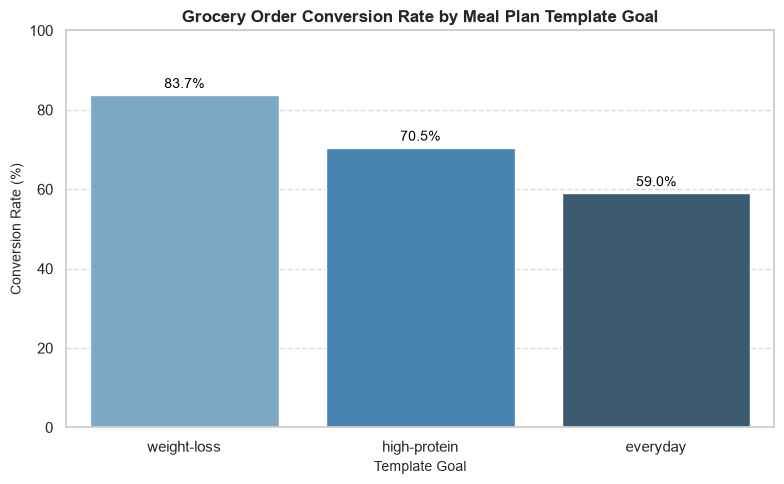

In [4]:
# Query plan-to-order conversion metrics grouped by template goal
query_conversion = "SELECT * FROM v_template_goal_conversion;"
df_conversion = pd.read_sql(query_conversion, engine)

display(df_conversion)

# Plot conversion rates across template goals
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_conversion,
    x='template_goal',
    y='conversion_rate_pct',
    palette='Blues_d',
    hue='template_goal',
    legend=False
)

plt.title(
    'Grocery Order Conversion Rate by Meal Plan Template Goal',
    fontsize=12,
    weight='bold',
)
plt.xlabel('Template Goal', fontsize=10)
plt.ylabel('Conversion Rate (%)', fontsize=10)
plt.ylim(0, 100)

# Add data labels on top of bars
for p in ax.patches:
  ax.annotate(
      f'{p.get_height():.1f}%',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=10,
      color='black',
      xytext=(0, 3),
      textcoords='offset points',
  )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 4. Household Repeat-Dish Intervals
Analyzing the `v_household_repeat_intervals` view to examine household fatigue patterns and repetition frequency.

,avg_repeat_interval_days,min_repeat_interval_days,total_repeats_tracked
count,290.000000,290.000000,290.000000
mean,27.083793,2.782759,52.634483
std,7.766420,2.491032,46.291137
min,4.000000,0.000000,1.000000
25%,26.125000,1.000000,38.000000
50%,29.800000,2.000000,47.000000
75%,32.000000,4.000000,53.000000
max,38.700000,17.000000,227.000000


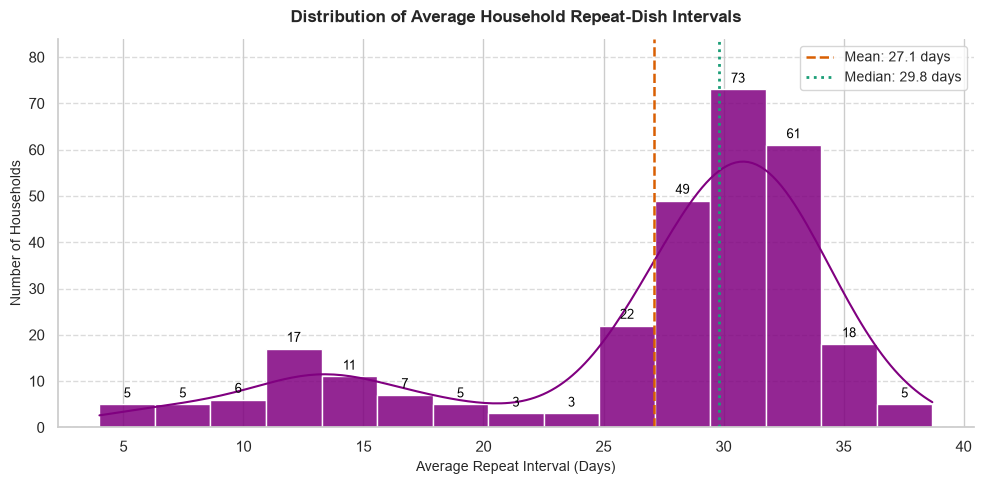

In [5]:
# Query household repeat intervals from the view
query_repeat_intervals = "SELECT * FROM v_household_repeat_intervals;"
df_repeat_intervals = pd.read_sql(query_repeat_intervals, engine)

display(df_repeat_intervals.describe())

# Plot distribution of average repeat intervals across households
plt.figure(figsize=(10, 5))
ax = sns.histplot(
    data=df_repeat_intervals,
    x='avg_repeat_interval_days',
    bins=15,
    kde=True,
    color='purple',
    edgecolor='white',
    alpha=0.85
)

# Calculate mean and median for reference lines
mean_val = df_repeat_intervals['avg_repeat_interval_days'].mean()
median_val = df_repeat_intervals['avg_repeat_interval_days'].median()

plt.axvline(mean_val, color='#d95f02', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.1f} days')
plt.axvline(median_val, color='#1b9e77', linestyle=':', linewidth=2.0, label=f'Median: {median_val:.1f} days')

plt.title('Distribution of Average Household Repeat-Dish Intervals', fontsize=12, weight='bold', pad=12)
plt.xlabel('Average Repeat Interval (Days)', fontsize=10)
plt.ylabel('Number of Households', fontsize=10)

# Add count labels above non-empty histogram bars
max_height = max([p.get_height() for p in ax.patches])
plt.ylim(0, max_height * 1.15)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.legend(frameon=True, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.despine()
plt.tight_layout()
plt.show()